# Splitting the part into tetrahedra and running Dijkstra

This notebook walks through the first stage of S4 Slicer, the big setup cell near the top of [main.ipynb](../main.ipynb). It takes a 3D model and works out, for every small piece of it, **how far it is from the build plate if you travel through the part**.

Why the slicer needs that:
- S4 Slicer prints overhangs by bending the part so each overhanging region is tilted into a printable angle. To choose the tilt direction it needs to know which way leads back to the base. It works that out from these distances, using the plane fit in [planeFit_explained.ipynb](planeFit_explained.ipynb).
- It also follows each route to the base to find pieces that hang underneath the rest of the part.

The steps:
1. Load the model's surface (the STL file).
2. Fill it with tetrahedra (TetGen).
3. Find which tetrahedra touch each other.
4. Turn that into a graph.
5. Find the tetrahedra sitting on the build plate.
6. Run Dijkstra from those to every other tetrahedron.
7. See why the graph uses tetrahedra that share a corner.
8. See what the slicer does with the results.

## 0. Setup

The model files are in `input_models/`, next to `main.ipynb`. To try another one, change `model_name`. With `pi 3mm` the whole notebook runs in about 15 seconds. The larger models (`z mount 3mm`, `B axis mount 5mm`) take a minute or more, mostly finding neighbours and building graphs.

In [23]:
import os
import heapq
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import open3d as o3d
import pyvista as pv
import tetgen
from scipy.spatial import cKDTree

# Same switch as main.ipynb: True gives rotatable 3D views, False gives static images
INTERACTIVE_PLOTS = True
if INTERACTIVE_PLOTS:
    try:
        pv.set_jupyter_backend('trame')
    except ImportError as e:
        print(f'Interactive plots unavailable ({e}). Falling back to static images.')
        pv.set_jupyter_backend('static')
else:
    pv.set_jupyter_backend('static')

def set_view(plotter):
    # one camera angle for every 3D view: from the front, a little to the side and above
    plotter.camera_position = "xz"
    plotter.camera.azimuth = 25
    plotter.camera.elevation = 20

model_name = "pi 3mm"
model_path = os.path.join("..", "input_models", f"{model_name}.stl")
print(os.path.abspath(model_path), "found" if os.path.isfile(model_path) else "NOT FOUND")

c:\Users\jackt\Downloads\S4_Slicer-main\S4_Slicer-main\input_models\pi 3mm.stl found


## 1. Load the surface

Here's the part, read straight from the STL file and sitting on the build plate (grey). The view from below shows the undersides that hang over empty space. Those are the overhangs S4 Slicer is designed to print.

In [ ]:
part = pv.read(model_path)
x_min, x_max, y_min, y_max, z_min, z_max = part.bounds
plate = pv.Plane(center=(part.center[0], part.center[1], z_min - 0.01 * (z_max - z_min)), direction=(0, 0, 1),
                 i_size=1.3 * (x_max - x_min) + 10, j_size=1.3 * (y_max - y_min) + 10)

pl = pv.Plotter(shape=(1, 2), window_size=(1200, 450))
for column, (label, elevation) in enumerate([("from above", 20), ("from below", -25)]):
    pl.subplot(0, column)
    pl.add_mesh(plate, color="grey", opacity=0.5 if elevation > 0 else 0.2)
    pl.add_mesh(part, color="light_blue", specular=0.4)
    pl.add_text(label, font_size=10)
    set_view(pl)
    pl.camera.elevation = elevation
    pl.camera.zoom(1.4)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19ce4b3c7d0_17&reconnect=auto" class="pyvi…

An STL file is just a list of triangles describing the **outside skin** of the part. It says nothing about the inside; there's nothing in there at all. That's enough to draw the part, but the slicer needs to bend the *solid* part, so it needs something that fills the volume.

`main.ipynb` loads the triangles with Open3D:

In [25]:
mesh = o3d.io.read_triangle_mesh(model_path)
surface_vertices = np.asarray(mesh.vertices)
surface_triangles = np.asarray(mesh.triangles)

print("vertices: ", surface_vertices.shape)
print("triangles:", surface_triangles.shape, " <- each row is 3 indices into the vertices")
print(surface_triangles[:3])

vertices:  (619, 3)
triangles: (870, 3)  <- each row is 3 indices into the vertices
[[0 1 2]
 [2 1 3]
 [2 3 4]]


The same surface with its triangles drawn on. Every flat side is made of triangles, and the STL file stores nothing else:

In [26]:
# PyVista wants each face written as [number of corners, corner indices...]
surface = pv.PolyData(surface_vertices, np.hstack([np.full((len(surface_triangles), 1), 3), surface_triangles]))

pl = pv.Plotter()
pl.add_mesh(surface, color="lightblue", show_edges=True)
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19d38edf9d0_8&reconnect=auto" class="pyvis…

## 2. Fill it with tetrahedra

A **tetrahedron** is the simplest solid: 4 corners, 6 edges and 4 triangular faces. Any solid can be filled with them, the same way any flat shape can be cut into triangles.

S4 Slicer uses them because:
- They can fill any shape, however complicated.
- Each one can be rotated and moved on its own, which is how the slicer bends the part.
- A point inside a tetrahedron can be described by how close it is to each of the 4 corners. When the corners move, the point moves with them. The slicer uses this at the end to carry the G-code through the bend.

[TetGen](https://wias-berlin.de/software/tetgen/) does the filling. `main.ipynb` calls it with its default settings, as here.

In [27]:
tg = tetgen.TetGen(surface_vertices, surface_triangles)
tg.tetrahedralize()
tet = tg.grid          # called input_tet in main.ipynb

distinct_corners = len(np.unique(surface_vertices, axis=0))
print("tetrahedra:", tet.number_of_cells)
print("points:    ", tet.number_of_points, f" (the surface has {distinct_corners} distinct corners; TetGen added any extra ones inside)")

tetrahedra: 1154
points:     443  (the surface has 437 distinct corners; TetGen added any extra ones inside)


`tet` is a PyVista `UnstructuredGrid`. Each tetrahedron is stored as 4 indices into `tet.points`. The raw `tet.cells` array writes every cell as `[4, a, b, c, d]`, where the leading 4 is the number of corners. That's why `main.ipynb` does `tet.cells.reshape(-1, 5)[:, 1:]`.

In [28]:
cells = tet.cells.reshape(-1, 5)[:, 1:]
print(cells[:3])
print("\ncorners of tetrahedron 0:\n", tet.points[cells[0]])

[[ 34  32 108 295]
 [253 252 251 442]
 [288  74  72 287]]

corners of tetrahedron 0:
 [[ -7.05882359  42.5         20.        ]
 [ -7.05882359  40.          20.        ]
 [-10.          42.5         17.5       ]
 [ -7.05882359  40.          17.1428566 ]]


The tetrahedra fill the part exactly, with no gaps or overlaps, so their volumes add up to the volume inside the surface:

In [29]:
print("tetrahedra, total volume:  %.2f mm³" % tet.volume)
print("volume inside the surface: %.2f mm³" % surface.volume)

tetrahedra, total volume:  7000.00 mm³
volume inside the surface: 7000.00 mm³


### Move the origin to the bottom centre

`main.ipynb` then shifts the part so the origin sits in the middle of its bottom: the centre of its bounding box in x and y, and its lowest point in z. This matters later, because the slicer measures "outward" from the z-axis through this origin.

In [30]:
x_min, x_max, y_min, y_max, z_min, z_max = tet.bounds
tet.points -= np.array([(x_min + x_max) / 2, (y_min + y_max) / 2, z_min])   # main.ipynb also adds PART_OFFSET, which is zero by default
print("bounds now:", np.round(tet.bounds, 2))

bounds now: [-25.  25.  -5.   5.   0.  20.]


### Look inside

Left: the part cut in half. The cut keeps whole tetrahedra, so you can see they fill the inside as well. Right: every tetrahedron shrunk towards its own centre, so you can see the separate pieces.

In [31]:
pl = pv.Plotter(shape=(1, 2), window_size=(1200, 450))
pl.subplot(0, 0)
pl.add_mesh(tet.clip(normal="-y", crinkle=True), color="lightblue", show_edges=True)
pl.add_text("cut in half", font_size=10)
pl.subplot(0, 1)
pl.add_mesh(tet.shrink(0.6), color="lightblue")
pl.add_text("each tetrahedron shrunk", font_size=10)
pl.link_views()
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19d38edcf50_9&reconnect=auto" class="pyvis…

## 3. Which tetrahedra touch?

Two tetrahedra can touch in three ways:
- **Face neighbours** share a whole triangle (3 corners). A tetrahedron has at most 4 of them.
- **Edge neighbours** share at least an edge (2 corners).
- **Point neighbours** share at least one corner.

Each kind includes the one before it: every face neighbour is also an edge neighbour, and every edge neighbour is also a point neighbour.

This loop is the one in `main.ipynb`. It records each touching pair once (`neighbour > cell_index`), then builds a neighbour list for every cell. (`main.ipynb` also saves the pairs in `input_tet.field_data["cell_point_neighbours"]` and so on.)

In [32]:
cell_neighbour_dict = {neighbour_type: {cell: [] for cell in range(tet.number_of_cells)} for neighbour_type in ["point", "edge", "face"]}
neighbour_pairs = {}
for neighbour_type in ["point", "edge", "face"]:
    pairs = []
    for cell_index in range(tet.number_of_cells):
        for neighbour in tet.cell_neighbors(cell_index, f"{neighbour_type}s"):
            if neighbour > cell_index:
                pairs.append((cell_index, neighbour))
    for cell_1, cell_2 in pairs:
        cell_neighbour_dict[neighbour_type][cell_1].append(cell_2)
        cell_neighbour_dict[neighbour_type][cell_2].append(cell_1)
    neighbour_pairs[neighbour_type] = np.array(pairs)
    print(f"{neighbour_type:5s} neighbours: {len(pairs):6d} pairs, {2 * len(pairs) / tet.number_of_cells:5.1f} per tetrahedron on average")

point neighbours:  32560 pairs,  56.4 per tetrahedron on average
edge  neighbours:   7394 pairs,  12.8 per tetrahedron on average
face  neighbours:   1873 pairs,   3.2 per tetrahedron on average


Here's one typical tetrahedron (red) and each kind of neighbour around it:

In [33]:
point_counts = np.array([len(cell_neighbour_dict["point"][c]) for c in range(tet.number_of_cells)])
example_cell = int(np.argsort(point_counts)[len(point_counts) // 2])   # a tetrahedron with a typical number of neighbours

pl = pv.Plotter(shape=(1, 3), window_size=(1500, 450))
for column, neighbour_type in enumerate(["face", "edge", "point"]):
    neighbours = cell_neighbour_dict[neighbour_type][example_cell]
    pl.subplot(0, column)
    pl.add_mesh(tet.extract_cells(example_cell), color="red")
    pl.add_mesh(tet.extract_cells(neighbours), color="lightblue", opacity=0.35, show_edges=True)
    pl.add_text(f"{neighbour_type} neighbours: {len(neighbours)}", font_size=10)
    set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19cdf836710_10&reconnect=auto" class="pyvi…

## 4. Turn it into a graph

Dijkstra works on a **graph**: dots (nodes) joined by lines (edges), where each line has a length (its weight). Here:
- **Nodes:** one per tetrahedron, at its centre.
- **Edges:** one between every pair of point neighbours.
- **Weight:** the straight-line distance between the two centres.

A path through the graph hops from centre to centre, so its total weight is roughly the distance you'd travel through the part. This is the same code as `main.ipynb`.

In [34]:
cell_centers = tet.cell_centers().points
cell_neighbour_graph = nx.Graph()
for cell_1, cell_2 in neighbour_pairs["point"]:   # use point neighbours for best accuracy (section 7 shows why)
    distance = np.linalg.norm(cell_centers[cell_1] - cell_centers[cell_2])
    cell_neighbour_graph.add_weighted_edges_from([(cell_1, cell_2, distance)])

print(cell_neighbour_graph)
print("all one piece:", nx.is_connected(cell_neighbour_graph))

Graph with 1154 nodes and 32560 edges
all one piece: True


The example tetrahedron's edges in the graph: one line from its centre (red) to each neighbour's centre (blue).

In [35]:
neighbours = cell_neighbour_dict["point"][example_cell]
segment_ends = np.empty((2 * len(neighbours), 3))
segment_ends[0::2] = cell_centers[example_cell]
segment_ends[1::2] = cell_centers[neighbours]

def balls(points, radius):
    # a small sphere at each point
    return pv.PolyData(np.atleast_2d(points)).glyph(geom=pv.Sphere(radius=radius), scale=False, orient=False)

neighbourhood = tet.extract_cells(neighbours)
pl = pv.Plotter()
pl.add_mesh(neighbourhood, color="lightblue", opacity=0.12)
pl.add_mesh(pv.line_segments_from_points(segment_ends), color="black", line_width=2)
pl.add_mesh(balls(cell_centers[neighbours], 0.012 * neighbourhood.length), color="royalblue")
pl.add_mesh(balls(cell_centers[example_cell], 0.025 * neighbourhood.length), color="red")
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19ce7318cd0_11&reconnect=auto" class="pyvi…

## 5. Find the tetrahedra on the build plate

Dijkstra needs somewhere to start: the tetrahedra resting on the build plate. A tetrahedron counts as a **bottom cell** if one of its faces is on the outside of the part and that face's centre is within 0.3 mm of the lowest face centre.

`main.ipynb` finds these inside `calculate_tet_attributes`, by matching surface vertices to tetrahedron corners. The code below gets the same cells more directly. `extract_surface` records which tetrahedron each outside triangle came from, in `vtkOriginalCellIds`. Both methods give an identical set of cells (checked on the `pi 3mm` model).

In [36]:
outer = tet.extract_surface(algorithm="dataset_surface")
face_centres = outer.cell_centers().points
owner = outer.cell_data["vtkOriginalCellIds"]     # which tetrahedron each outside triangle belongs to

on_plate = face_centres[:, 2] < face_centres[:, 2].min() + 0.3
bottom_cells = np.unique(owner[on_plate])
print(f"{len(bottom_cells)} bottom cells out of {tet.number_of_cells}")

64 bottom cells out of 1154


In [37]:
tet.cell_data["is_bottom"] = np.isin(np.arange(tet.number_of_cells), bottom_cells)

pl = pv.Plotter()
pl.add_mesh(tet, scalars="is_bottom", cmap=["lightgrey", "crimson"], show_edges=True, show_scalar_bar=False)
set_view(pl)
pl.camera.elevation = -25      # look from slightly below
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19ce731b610_12&reconnect=auto" class="pyvi…

## 6. Run Dijkstra

Dijkstra's algorithm finds the shortest route from a starting point to every node in a graph. Here there are many starting points: every bottom cell starts at distance 0. It's as if the whole build plate were one starting node.

How it works:
1. Keep a to-do list of cells, sorted by the shortest distance found to each so far. At the start it holds just the bottom cells, at 0.
2. Take the closest cell off the list. Its distance is now final. Any other route would have to pass through a cell that's already further away.
3. For each of its neighbours, check whether going through this cell is shorter than the best route known so far. If it is, record the new distance and which cell it came from, and put the neighbour on the list.
4. Repeat until the list is empty.

Cells are finished in order of distance, so the finished region grows out from the build plate like a wave. The animation further down shows this.

Here it is written out, using Python's `heapq` to keep the to-do list sorted:

In [38]:
def dijkstra(graph, sources):
    dist = {s: 0.0 for s in sources}
    came_from = {}
    to_do = [(0.0, s) for s in sources]
    heapq.heapify(to_do)
    finished = set()
    while to_do:
        d, cell = heapq.heappop(to_do)          # the closest cell not yet finished
        if cell in finished:
            continue                            # an old, longer entry for a cell we've already done
        finished.add(cell)
        for neighbour, edge in graph[cell].items():
            new_d = d + edge["weight"]
            if new_d < dist.get(neighbour, np.inf):   # found a shorter way to this neighbour
                dist[neighbour] = new_d
                came_from[neighbour] = cell
                heapq.heappush(to_do, (new_d, neighbour))
    return dist, came_from

dist_by_hand, came_from = dijkstra(cell_neighbour_graph, bottom_cells)
print("cells reached:", len(dist_by_hand), "of", tet.number_of_cells)

cells reached: 1154 of 1154


`main.ipynb` uses NetworkX's version. It does the same thing and also returns the full path to each cell. Each path starts at a bottom cell and ends at the cell itself, which is why `main.ipynb` uses `paths_to_bottom[cell][0]` to get a cell's closest bottom cell.

In [39]:
distances_to_bottom, paths_to_bottom = nx.multi_source_dijkstra(cell_neighbour_graph, set(bottom_cells))

largest_difference = max(abs(distances_to_bottom[c] - dist_by_hand[c]) for c in range(tet.number_of_cells))
print("largest difference from the hand-written version:", largest_difference)

far_cell = max(distances_to_bottom, key=distances_to_bottom.get)
print(f"\nfurthest cell: {far_cell}, {distances_to_bottom[far_cell]:.2f} mm from the plate")
print("its path:", [int(c) for c in paths_to_bottom[far_cell]])

largest difference from the hand-written version: 0.0

furthest cell: 1145, 23.02 mm from the plate
its path: [940, 877, 1025, 741, 799, 224, 135, 1145]


Below, every tetrahedron is coloured by its distance. Drawn on top is the route for the cell whose path is longest compared with its height. It sits under one end of the bar, so it has to travel sideways to a leg before it can go down. The tetrahedra the path passes through are orange, and the red line joins their centres.

In [40]:
tet.cell_data["distance_to_bottom"] = np.array([distances_to_bottom[c] for c in range(tet.number_of_cells)])
detour_cell = int(np.argmax(tet.cell_data["distance_to_bottom"] - cell_centers[:, 2]))   # longest route compared with its height
path = paths_to_bottom[detour_cell]
print(f"cell {detour_cell}: {cell_centers[detour_cell, 2]:.1f} mm up, but {distances_to_bottom[detour_cell]:.1f} mm from the plate through the part")

pl = pv.Plotter()
pl.add_mesh(tet, scalars="distance_to_bottom", cmap="viridis", opacity=0.15)
pl.add_mesh(tet.extract_cells(path), color="orange", opacity=0.5, show_edges=True)
pl.add_mesh(pv.lines_from_points(cell_centers[path]), color="red", line_width=6)
pl.add_mesh(balls(cell_centers[path], 0.008 * tet.length), color="red")
set_view(pl)
pl.show()

cell 1020: 10.6 mm up, but 19.7 mm from the plate through the part


Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19cdf835bd0_13&reconnect=auto" class="pyvi…

### Watch it spread

Each frame shows the cells Dijkstra has finished by the time it reaches a given distance. The frames are drawn off-screen with PyVista, then played with the same player as the plane-fit notebook. Rendering takes a few seconds.

In [41]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

distance = tet.cell_data["distance_to_bottom"]
steps = np.linspace(0, distance.max(), 40)

pl = pv.Plotter(off_screen=True, window_size=(800, 480))
pl.add_mesh(outer, color="lightgrey", opacity=0.15)
set_view(pl)
frames = []
for reached in list(steps) + [steps[-1]] * 8:          # repeat the last frame so it pauses at the end
    finished = tet.extract_cells(np.where(distance <= reached)[0])
    actor = pl.add_mesh(finished, scalars="distance_to_bottom", cmap="viridis", clim=[0, distance.max()], show_scalar_bar=False)
    pl.add_text(f"finished up to {reached:4.1f} mm from the plate", name="label", font_size=12)
    frames.append(pl.screenshot(return_img=True))
    pl.remove_actor(actor)
pl.close()

fig = plt.figure(figsize=(8, 4.8), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.axis("off")
image = ax.imshow(frames[0])
anim = FuncAnimation(fig, lambda i: image.set_data(frames[i]), frames=len(frames))
plt.close(fig)   # stop Jupyter also showing the last frame as a still image
with plt.rc_context({"animation.frame_format": "jpeg"}):   # jpeg frames keep the notebook small
    player = anim.to_jshtml(fps=8, default_mode="once")
HTML(player)

## 7. Why point neighbours?

`main.ipynb` builds the graph from point neighbours, with the comment "use point neighbours for best accuracy". Here's what that buys.

A path through the graph zig-zags from centre to centre, so it's always at least as long as a straight line. The more neighbours each cell has, the more directions it can step in, so the path can stay closer to straight.

The cell below runs Dijkstra on all three kinds of graph. For each, it compares every cell's path length with the straight-line distance to its nearest bottom cell. Cells within 3 mm of the plate are left out because the ratio is noisy there. It's a rough check: on some shapes the straight line passes through air, but the median is dominated by cells that can see the plate directly.

In [42]:
straight_line, _ = cKDTree(cell_centers[bottom_cells]).query(cell_centers)
far_enough = straight_line > 3

for neighbour_type in ["face", "edge", "point"]:
    graph = nx.Graph()
    for cell_1, cell_2 in neighbour_pairs[neighbour_type]:
        graph.add_edge(cell_1, cell_2, weight=np.linalg.norm(cell_centers[cell_1] - cell_centers[cell_2]))
    d, _ = nx.multi_source_dijkstra(graph, set(bottom_cells))
    d = np.array([d.get(c, np.nan) for c in range(tet.number_of_cells)])
    stretch = np.nanmedian(d[far_enough] / straight_line[far_enough])
    print(f"{neighbour_type:5s} neighbours: paths are {100 * (stretch - 1):4.1f}% longer than a straight line (median)")

face  neighbours: paths are 44.9% longer than a straight line (median)
edge  neighbours: paths are 11.7% longer than a straight line (median)
point neighbours: paths are  2.6% longer than a straight line (median)


## 8. What the slicer does with the results

### Distances: which way to tilt

In `calculate_path_length_to_base_gradient`, the slicer keeps the distance only for overhanging cells. For each one it fits a plane through (x, y, distance) for the cell and its neighbours, and reads off which way the distance increases. That's covered in [planeFit_explained.ipynb](planeFit_explained.ipynb).

To see where the long routes are, plot each cell's distance against its height. A cell that can go straight down sits on the dashed line, where distance ≈ height. A cell above the line has to take a detour, like the ends of the π's top bar, which have to travel sideways to a leg first.

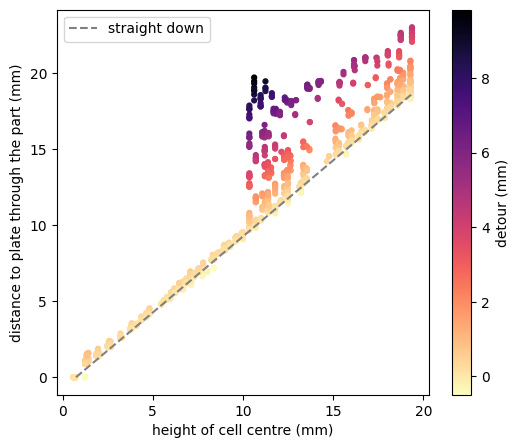

In [43]:
heights = cell_centers[:, 2]
plate_level = heights[bottom_cells].mean()     # bottom cell centres sit a little above z = 0
detour = distance - (heights - plate_level)

fig, ax = plt.subplots(figsize=(6, 5))
points = ax.scatter(heights, distance, c=detour, cmap="magma_r", s=12)
line = np.array([plate_level, heights.max()])
ax.plot(line, line - plate_level, "--", color="grey", label="straight down")
ax.set_xlabel("height of cell centre (mm)")
ax.set_ylabel("distance to plate through the part (mm)")
ax.legend()
fig.colorbar(points, label="detour (mm)")
plt.show()

In [44]:
tet.cell_data["detour"] = detour

pl = pv.Plotter()
pl.add_mesh(tet, scalars="detour", cmap="magma_r", show_edges=True)
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:64857/index.html?ui=P_0x19d08dd6ad0_14&reconnect=auto" class="pyvi…

### Paths: cells hanging in the air

`update_tet_attributes` also walks along each cell's path. If any cell on the path is more than 1 mm **higher** than the cell itself, the route to the plate has to climb over something, which means the cell hangs underneath other material. Those cells are flagged `in_air`. They're the very steep overhangs that the `STEEP_OVERHANG_COMPENSATION` option is for. Same code as `main.ipynb`:

In [45]:
IN_AIR_THRESHOLD = 1
in_air = np.zeros(tet.number_of_cells, dtype=bool)
for cell_index in range(tet.number_of_cells):
    path_to_bottom = paths_to_bottom[cell_index]
    if len(path_to_bottom) > 1:
        if np.any(cell_centers[path_to_bottom, 2] > cell_centers[cell_index, 2] + IN_AIR_THRESHOLD):
            in_air[cell_index] = True
print(f"{in_air.sum()} cells in the air")

if in_air.any():
    tet.cell_data["in_air"] = in_air
    pl = pv.Plotter()
    pl.add_mesh(tet, scalars="in_air", cmap=["lightgrey", "crimson"], show_scalar_bar=False)
    set_view(pl)
    pl.show()

0 cells in the air


The π has none: every cell's route to the plate goes sideways or down. To see a model that has some, set `model_name = "B axis mount 5mm"` in the setup cell and run everything again. It has 844, on its side arm.

## Summary

- An STL file is only a skin. TetGen fills it with tetrahedra, so the slicer has something solid to bend.
- Tetrahedra that share at least one corner are point neighbours. The graph has one node per tetrahedron and one edge per neighbour pair, weighted by the distance between their centres.
- Bottom cells are the tetrahedra with an outside face on the build plate.
- Multi-source Dijkstra gives every tetrahedron its shortest distance through the part to the plate, and the path that gets it there.
- The slicer uses the distances to choose which way overhangs tilt (via `planeFit`), and the paths to flag cells hanging in the air.